# Módulo 3 — Tacograma y frecuencia cardíaca

| | |
|---|---|
| **Responde** | ítems 6a y 6b |
| **Código** | `tacograma.py` (en esta misma carpeta) |
| **Recibe** | las posiciones de los picos R y `fs` |
| **Devuelve** | `t_rr` y `rr` en segundos (ver la convención en `tacograma.py`) |
| **Responsable** | Cassano Nieto |

> Las funciones se programan en `tacograma.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: correr `python main.py` desde la carpeta del repo.

In [1]:
# --- Configuración del cuaderno ---
# El cuaderno está en modulos/m3_tacograma/; "../.." es la raíz del repo.
import sys
sys.path.insert(0, "../..")

# Recarga los cambios de los archivos .py sin reiniciar el kernel
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modulos.m3_tacograma import tacograma
from modulos.m1_acondicionamiento import acondicionamiento as acond
from modulos.herramientas import ecg_de_prueba, graficos
from modulos.herramientas.procesamiento_completo import procesar_todos

graficos.aplicar_estilo()
print(f"Atípicos: más de {100 * tacograma.UMBRAL_ATIPICOS:.0f} % de la mediana de {tacograma.VENTANA_ATIPICOS} RR")

Atípicos: más de 30 % de la mediana de 11 RR


## Prueba con picos inventados

`generar_ecg()` da las posiciones exactas de los picos R de un ECG sintético a 70 lpm cuyo RR oscila un 5 % a 0,25 Hz.
El tacograma tiene que tener un elemento menos que los picos, RR medio de 60/70 = 857 ms y FC media de 70 lpm.

69 picos -> 68 RR;  RR medio 857 ms;  FC media 70.1 lpm


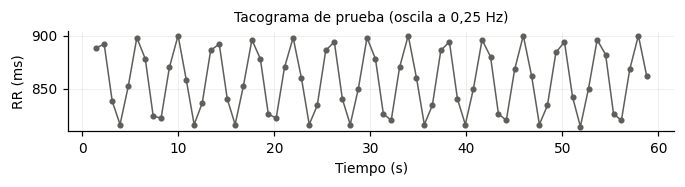

In [2]:
fs_prueba = 500
_, _, picos_prueba = ecg_de_prueba.generar_ecg(fs=fs_prueba, duracion=60, fc_media=70, amp_mod=0.05, semilla=0)
t_rr, rr = tacograma.intervalos_rr(picos_prueba, fs_prueba)
print(f"{len(picos_prueba)} picos -> {len(rr)} RR;  RR medio {1000 * rr.mean():.0f} ms;  "
      f"FC media {tacograma.frecuencia_cardiaca(rr).mean():.1f} lpm")

fig, ax = plt.subplots(figsize=(16 / 2.54, 4.5 / 2.54))
ax.plot(t_rr, 1000 * rr, ".-", color=graficos.COLOR_NEUTRO)
ax.set(xlabel="Tiempo (s)", ylabel="RR (ms)", title="Tacograma de prueba (oscila a 0,25 Hz)")
fig.tight_layout()

## Tacogramas de los registros

`procesar_todos(hasta="tacograma")` corre M0 → M1 → M2 → M3. El tacograma se arma con
`tacograma.intervalos_rr(picos_r, fs, valida)`, donde `valida` es la máscara de muestras aptas de M1
(`mascara_valida`: el primer segundo y los tramos saturados, con 0,2 s de margen).

**Regla para usar un intervalo**: ninguna muestra entre sus dos latidos puede ser inválida. No alcanza con mirar los
dos latidos de los extremos: si un latido cae dentro de un tramo saturado y no se detecta, el intervalo que lo
contiene mide el doble aunque sus extremos estén en zona válida.

In [3]:
resultados = procesar_todos(hasta="tacograma")

filas = {}
for res in resultados:
    reg = res.registro
    filas[reg.nombre] = {"latidos": len(res.picos_r), "RR posibles": len(res.picos_r) - 1,
                         "RR en zona válida": len(res.rr), "RR atípicos": int(tacograma.rr_atipicos(res.rr).sum())}
pd.DataFrame.from_dict(filas, orient="index")

,latidos,RR posibles,RR en zona válida,RR atípicos
V1_reposo,80,79,78,0
V1_post_ejercicio,375,374,359,0


Comparación entre las dos reglas posibles para descartar intervalos: mirar sólo los latidos de los extremos o mirar
todo el intervalo. Con la primera quedan intervalos que contienen un latido perdido dentro de una saturación.

In [4]:
for res in resultados:
    picos, valida, fs = res.picos_r, res.valida, res.registro.fs
    extremos = valida[picos[1:]] & valida[picos[:-1]]
    rr_extremos = (np.diff(picos) / fs)[extremos]
    _, rr_todo = tacograma.intervalos_rr(picos, fs, valida)
    print(f"{res.registro.nombre:20s} sólo extremos: {len(rr_extremos)} RR, {tacograma.rr_atipicos(rr_extremos).sum()} atípicos   "
          f"todo el intervalo: {len(rr_todo)} RR, {tacograma.rr_atipicos(rr_todo).sum()} atípicos")

V1_reposo            sólo extremos: 78 RR, 0 atípicos   todo el intervalo: 78 RR, 0 atípicos
V1_post_ejercicio    sólo extremos: 361 RR, 2 atípicos   todo el intervalo: 359 RR, 0 atípicos


## Ítem 6a — ¿Cómo varía la frecuencia cardíaca en cada registro?

Figura del informe: tacograma y frecuencia cardíaca instantánea de los dos registros en los mismos ejes, con el
tiempo desde el inicio de cada registro.

WindowsPath('D:/Datos Facu No Borrar/Escritorio/Labo ECG y HRV PSIB/informe/figuras/tacogramas.pdf')

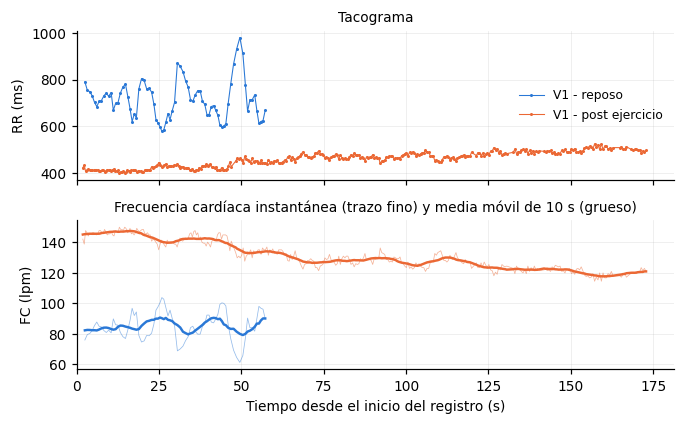

In [5]:
fig = tacograma.figura_tacogramas(resultados)
graficos.guardar_figura(fig, "tacogramas")

Índices del tacograma (`tacograma.resumen`), sin los RR atípicos:

- **FC**: media, mínima y máxima instantáneas, media de los primeros y últimos 10 s, y pendiente de la recta ajustada a
  la FC instantánea (lpm por minuto).
- **SDNN**: desvío estándar de los RR, la variabilidad total (incluye la tendencia).
- **RMSSD** y **pNN50**: variabilidad latido a latido, a partir de las diferencias entre RR consecutivos; se las asocia
  al tono vagal (Task Force, 1996).

In [6]:
tabla = pd.DataFrame.from_dict({res.registro.nombre: tacograma.resumen(res.t_rr, res.rr) for res in resultados},
                               orient="index")
tabla.round(1).T

,V1_reposo,V1_post_ejercicio
N_RR,78.0,359.0
atipicos,0.0,0.0
duracion_s,54.8,171.0
FC_media_lpm,84.2,130.9
FC_min_lpm,61.2,114.5
FC_max_lpm,103.8,150.0
FC_inicio_lpm,82.9,145.7
FC_fin_lpm,80.2,120.1
pendiente_FC_lpm_min,2.9,-10.4
RR_medio_ms,712.3,458.4


La SDNN del post ejercicio mezcla la variabilidad latido a latido con la caída sostenida de la FC. Para separarlas,
la recalculamos después de quitarle al tacograma la misma tendencia polinómica de grado 2 que quita M4 antes del
periodograma. También medimos cuánto baja la FC en el primer minuto del registro.

In [7]:
from modulos.m4_periodograma_lomb import periodograma_lomb as lomb

for res in resultados:
    t, x = lomb.preparar_tacograma(res.t_rr, res.rr)
    print(f"{res.registro.nombre:20s} SDNN sin tendencia: {1000 * x.std(ddof=1):5.1f} ms")

post = next(res for res in resultados if res.registro.condicion == "post_ejercicio")
ok = ~tacograma.rr_atipicos(post.rr)
t, fc = post.t_rr[ok], tacograma.frecuencia_cardiaca(post.rr[ok])
for t0 in (0, 60, 120):
    sel = (t >= t[0] + t0) & (t < t[0] + t0 + 60)
    print(f"Post ejercicio, minuto {t0 // 60 + 1}: FC media {60 / post.rr[ok][sel].mean():5.1f} lpm, "
          f"pendiente {60 * np.polyfit(t[sel], fc[sel], 1)[0]:+5.1f} lpm/min")

V1_reposo            SDNN sin tendencia:  81.7 ms
V1_post_ejercicio    SDNN sin tendencia:  12.0 ms
Post ejercicio, minuto 1: FC media 141.3 lpm, pendiente -14.5 lpm/min
Post ejercicio, minuto 2: FC media 128.0 lpm, pendiente  -1.2 lpm/min
Post ejercicio, minuto 3: FC media 121.2 lpm, pendiente  -6.0 lpm/min


**Qué se ve (V1)**

- **Reposo** (84 lpm de media): la FC no tiene tendencia, pero oscila mucho, entre 61 y 104 lpm. Se ven dos o tres
  oscilaciones lentas grandes, de unos 15-20 s de período (el RR va de ~600 a ~980 ms), y sobre ellas una
  ondulación más rápida, latido a latido. La variabilidad es alta: SDNN de 82 ms, RMSSD de 48 ms y pNN50 del 23 %.
- **Post ejercicio** (131 lpm de media): la FC empieza en ~146 lpm, se mantiene en esa meseta unos 20 s y después
  baja en forma sostenida hasta ~120 lpm al final del registro (pendiente media de −10 lpm/min: −14,5 lpm/min en el
  primer minuto, −1,2 en el segundo y −6,0 en el tercero). La variabilidad latido a latido casi desaparece: RMSSD de 8,6 ms (5,6 veces menos que en
  reposo) y ninguna diferencia sucesiva mayor a 50 ms. La SDNN (32 ms) está dominada por la tendencia; sin ella queda
  en unos 12 ms.

## Ítem 6b — ¿Sucede de igual manera con ambos voluntarios?

Se registró un solo voluntario (V1), así que no hay comparación entre voluntarios. Las funciones y la figura ya están
preparadas para un segundo voluntario: alcanza con agregar sus archivos a `datos/lista_de_registros.csv` (en la figura,
V2 aparece con línea discontinua).